# Analyse the retained Part B full run

This notebook reads the **user's actual full-run CSVs** for `20261110_044740_8e7cd654`; it does not compile or run CUDA. Saved outputs below were regenerated from those files during packaging. Open from the delivered `part_b/notebooks` folder and Run All to recheck the evidence and display tables/figures. The separate Lab notebook builds fresh CUDA experiments and retains an older smoke example.

**Status:** 165 numerical checks PASS; 1,800 timing samples. The diagnostic overall audit remains false because the user omitted sanitizers and profiling. No A/B speedup, safety certificate or fresh hardware counters are claimed.

In [1]:
from pathlib import Path
import csv,hashlib,json,html
from IPython.display import display,HTML,Markdown,Image
here=Path.cwd().resolve()
candidates=[here]+list(here.parents)
B=next((p for p in candidates if (p/'results/notebook_full_20261110_044740').is_dir()),None)
if B is None:
    B=next((p/'part_b' for p in candidates if (p/'part_b/results/notebook_full_20261110_044740').is_dir()),None)
if B is None:raise FileNotFoundError('Open from the delivered part_b/notebooks folder or repository.')
bundle=B/'results/notebook_full_20261110_044740'
def read(name):
    with (bundle/(name+'.csv')).open(newline='',encoding='utf-8') as f:return list(csv.DictReader(f))
def table(rows):
    keys=list(rows[0]);s='<table><tr>'+''.join('<th>'+html.escape(k)+'</th>' for k in keys)+'</tr>'
    for row in rows:s+='<tr>'+''.join('<td>'+html.escape(str(row[k]))+'</td>' for k in keys)+'</tr>'
    display(HTML(s+'</table>'))
index=json.loads((bundle/'raw/part_b/index.json').read_text())
for name,value in index['evidence_hashes'].items():
    assert hashlib.sha256((bundle/name).read_bytes()).hexdigest()==value,name
checks=read('correctness');samples=read('samples');summary=read('summary')
assert len(checks)==165 and len(samples)==1800 and len(summary)==90
assert all(r['status']=='PASS' and int(r['failures'])==0 and int(r['nonfinite'])==0 for r in checks)
audit=json.loads((bundle/'audit.json').read_text())
print('PASS: immutable native-evidence hashes and zero numerical failures')
print('Full checks:',sum(r['reference_scope']=='full' for r in checks),'Sampled:',sum(r['reference_scope']=='sampled' for r in checks))
print('Timing cases:',len(summary),'Samples:',len(samples))
print('Overall evidence audit:',audit['passed'],'; sanitizer checks:',audit['sanitizer_checks'],'; profiles:',audit['profile_captures'])
print('Measured source: namespace dense_attention; do not attribute these results to the different b0-b3 implementation.')


PASS: immutable native-evidence hashes and zero numerical failures
Full checks: 75 Sampled: 90
Timing cases: 90 Samples: 1800
Overall evidence audit: False ; sanitizer checks: 0 ; profiles: 0
Measured source: namespace dense_attention; do not attribute these results to the different b0-b3 implementation.


## Frozen main series
B4/H8; selected configurations are frozen on N256/1024. The other lengths are held out. Each case has 20 samples after 5 warmups. Displayed medians are not retrospective minima over the main grid.

In [2]:
selected=[r for r in summary if r['experiment']=='proposal' and r['variant']=='selected']
table([{'N':r['N'],'d':r['d'],'config':r['config'],'median_ms':round(float(r['forward_median_ms']),4),'IQR_ms':round(float(r['forward_iqr_ms']),4),'live_MiB':int(r['peak_workspace_allocated_bytes'])/2**20} for r in selected])


N,d,config,median_ms,IQR_ms,live_MiB
256,32,vector_w4_k64,0.4454,0.0077,4.0
512,32,vector_w4_k64,1.7305,0.0031,8.0
1024,32,vector_w4_k64,7.0807,0.2586,16.0
2048,32,vector_w4_k64,28.1256,0.2659,32.0
4096,32,vector_w4_k64,112.0532,0.7747,64.0
256,64,vector_w4_k32,0.4977,0.0008,8.0
512,64,vector_w4_k32,1.9323,0.0197,16.0
1024,64,vector_w4_k32,7.8694,0.2079,32.0
2048,64,vector_w4_k32,31.2043,0.433,64.0
4096,64,vector_w4_k32,125.168,0.6887,128.0


## Matched scalar versus float4 loading
Only W4/BK32 scalar/vector pairs are used. Ratios greater than 1 favour float4. These are within-B comparisons, not speedups over A.

In [3]:
main=[r for r in summary if r['experiment']=='proposal']
comparison=[]
for r in [r for r in main if r['variant']=='tiled' and r['N']=='4096']:
    v=next(x for x in main if x['variant']=='vector' and all(x[k]==r[k] for k in ['B','H','N','d','input_digest']))
    a,b=float(r['forward_median_ms']),float(v['forward_median_ms'])
    comparison.append({'d':r['d'],'scalar_ms':round(a,4),'float4_ms':round(b,4),'speedup':round(a/b,3),'time_reduction_percent':round(100*(1-b/a),1)})
table(comparison)


d,scalar_ms,float4_ms,speedup,time_reduction_percent
32,118.382,113.7836,1.04,3.9
64,147.2267,135.0062,1.091,8.3
128,283.1886,225.5365,1.256,20.4


## Figures
These plots are derived from the same retained full-run records. Shading is Q1-Q3 within a timing case. Same configurations in separate series were timed separately; close differences can reflect order, clocks and display activity.

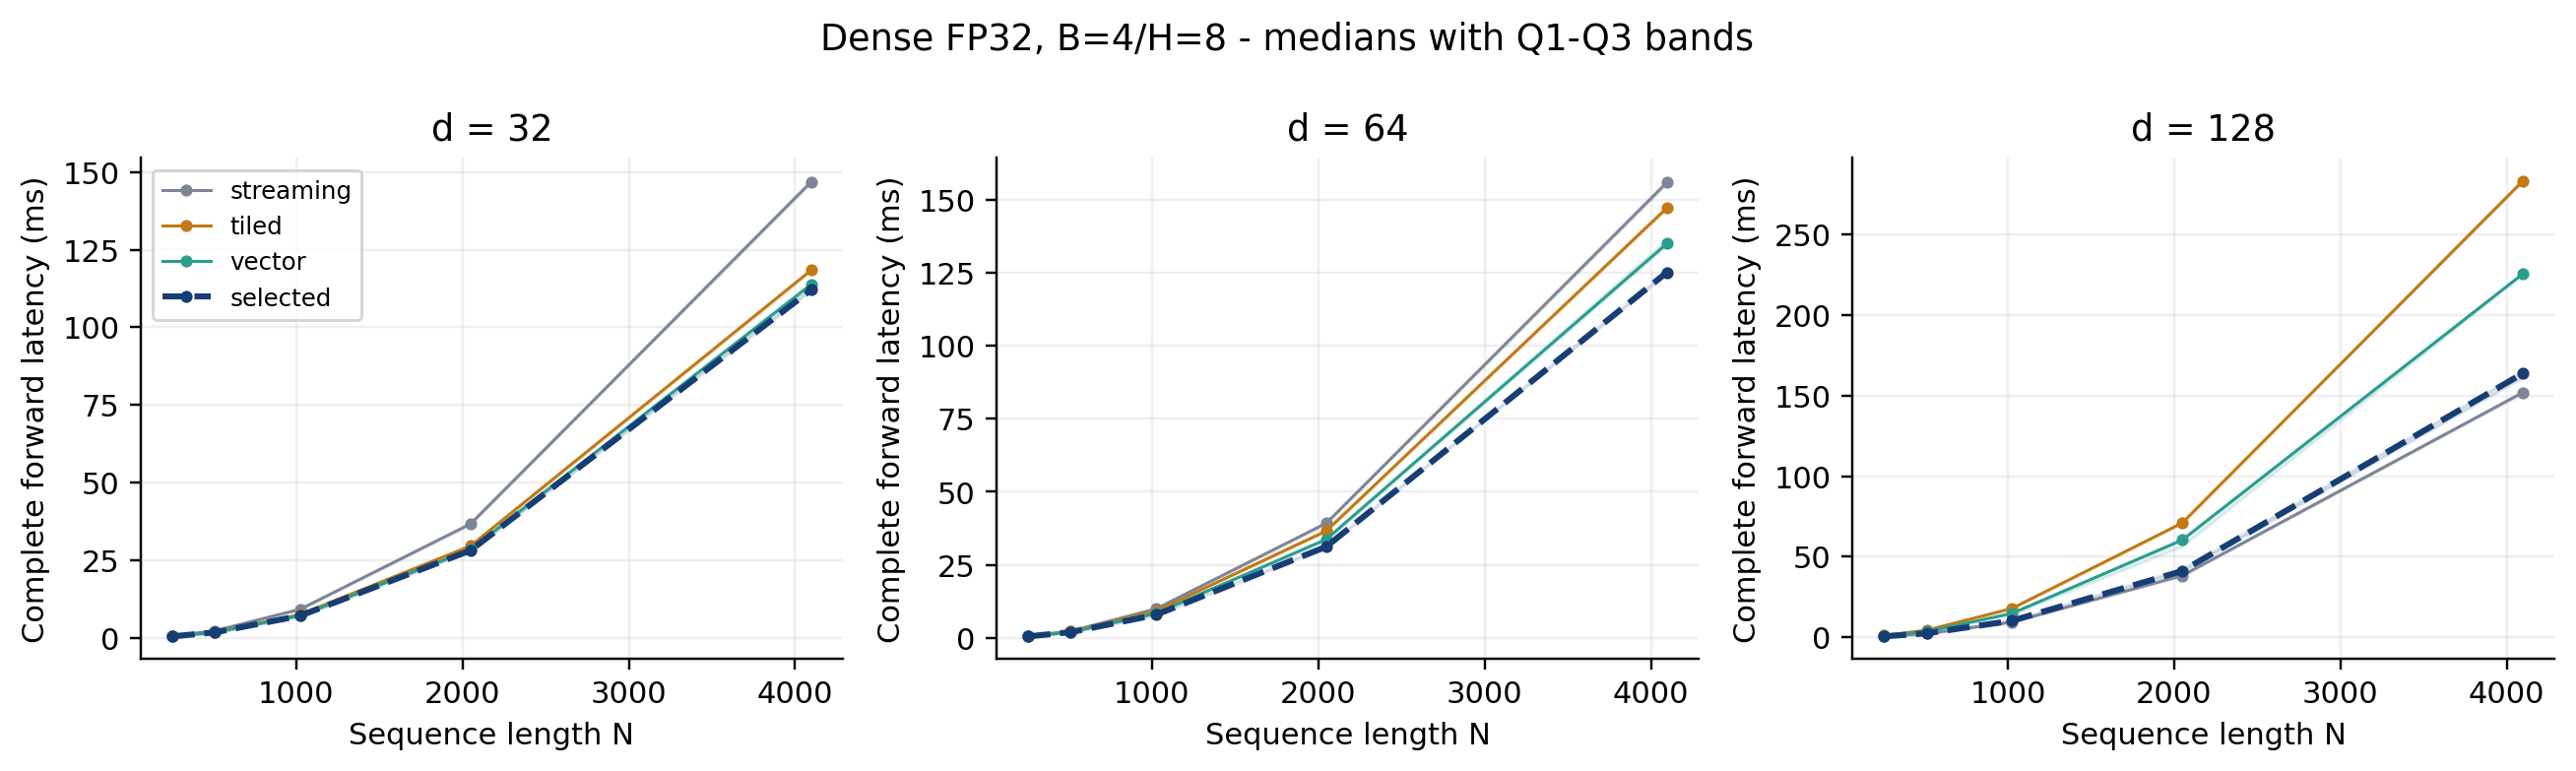

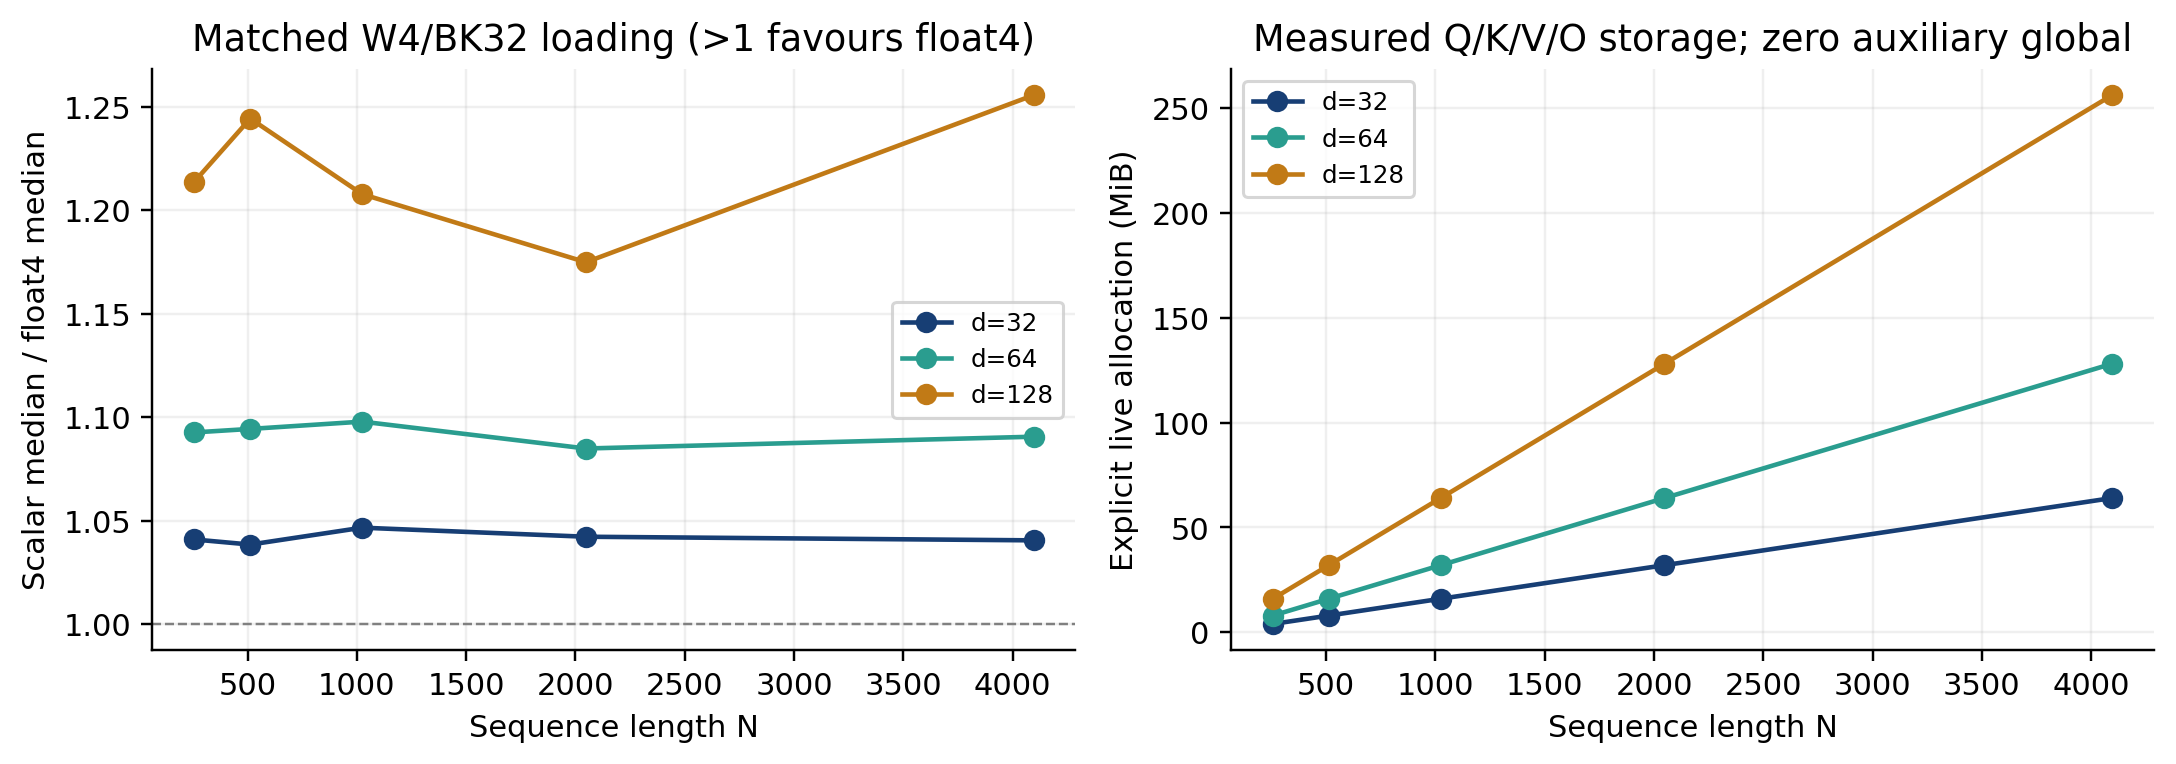

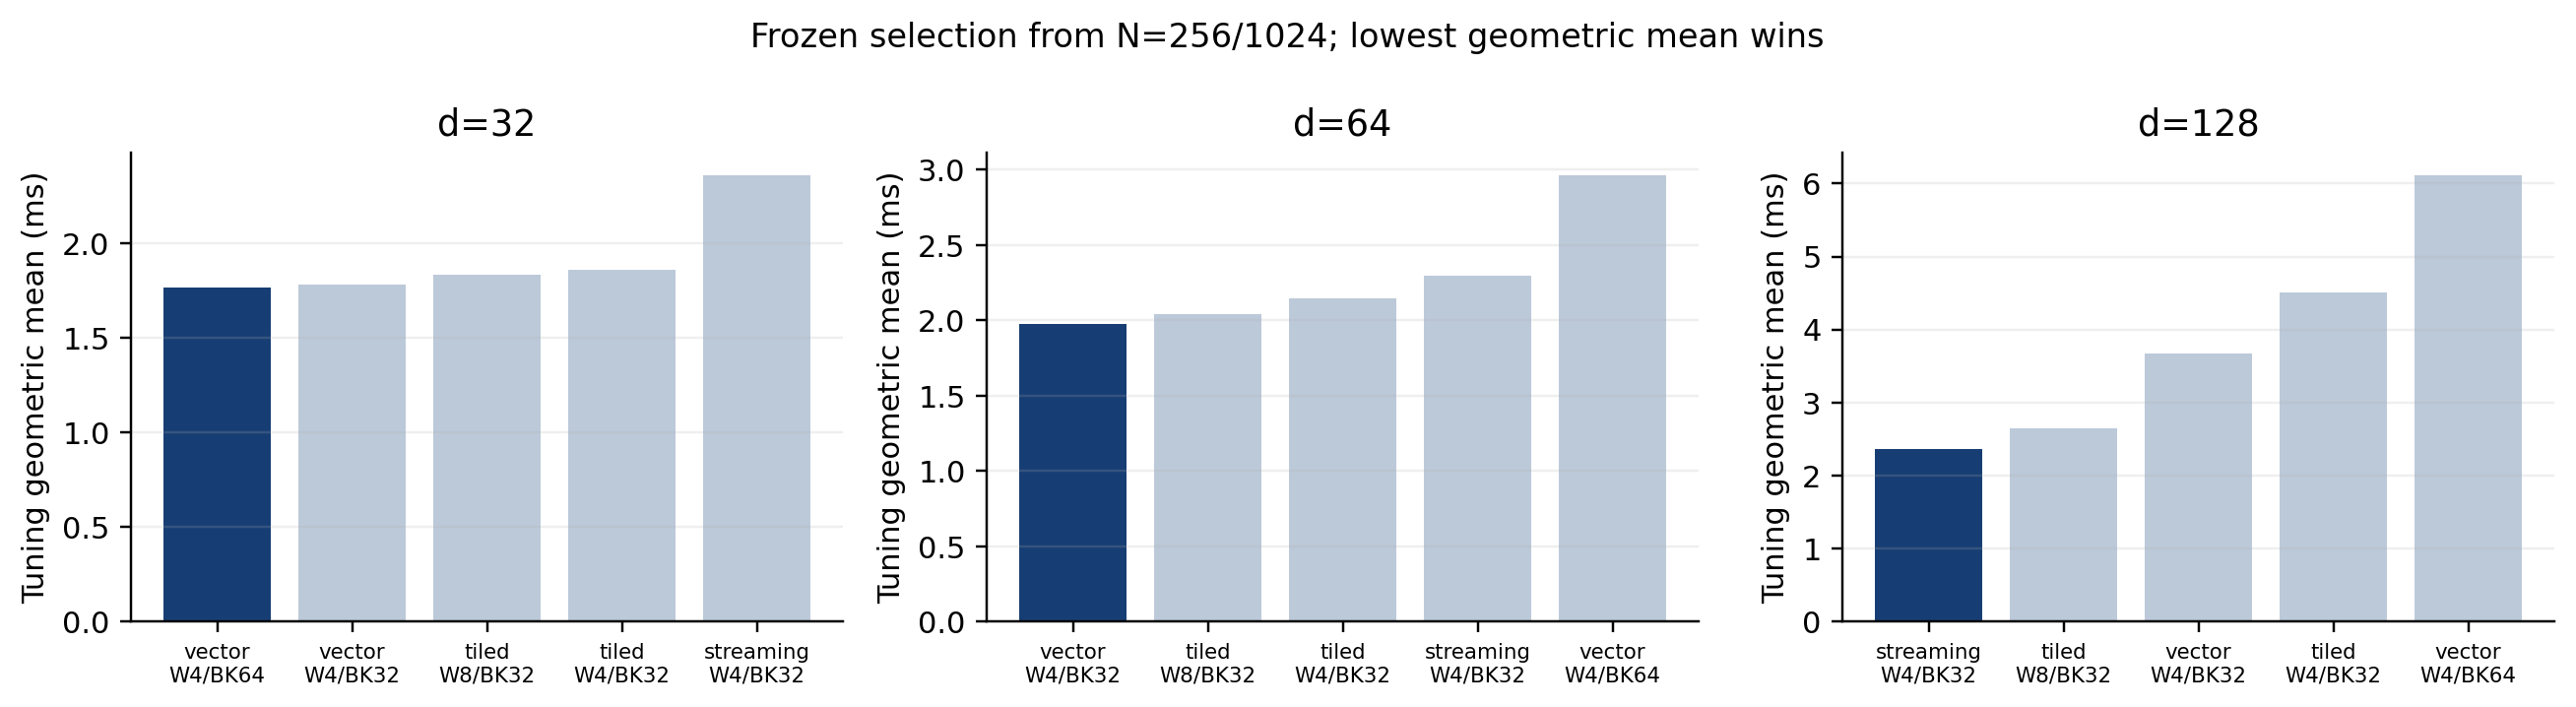

In [4]:
figures=bundle/'supplementary/part_b/submission'
for name in ['part_b_latency.png','part_b_loading_memory.png','part_b_tuning.png']:
    display(Image(filename=str(figures/name)))


## Reproduce the analysis

From the installed complete repository: `python part_b/scripts/analyze_delivery.py --verify-only` performs the full shared-schema/statistics and provenance audit; omitting that flag regenerates figures/tables. No CUDA is used by that analysis script.

The full-run toolkit was CUDA 12.9 / nvcc 12.9.41, MSVC 19.41, RTX 4070 Ti SM89, driver 621.01. At N4096,d64 the explicit live Q/K/V/O ledger is 128 MiB and auxiliary global allocation is zero. The comparison to 4,224 MiB materialised storage in the report is analytical, not a measured Part A allocation from this run. The final same-GPU A/B/C study and sanitizer/profiler evidence remain outstanding.